In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
BASE = '/content/drive/MyDrive/Akhila-portfolio/Project1-data/'
claims = pd.read_csv(BASE + 'cleaned_all_claims.csv')
patient = pd.read_csv(BASE + 'patient_summary.csv')
print(len(claims), len(patient))

/tmp/ipykernel_1341/3250333189.py:4: DtypeWarning: Columns (5,6) have mixed types. Specify dtype option on import or set low_memory=False.
  claims = pd.read_csv(BASE + 'cleaned_all_claims.csv')


5598898 99226


In [3]:
by_type = claims.groupby('claim_type')['paid_amt'].agg(['count','sum','mean'])
by_type

,count,sum,mean
claim_type,,,
Carrier,4741335,414603690.0,87.444505
Inpatient,66773,639260180.0,9573.632756
Outpatient,790790,224524710.0,283.924569


In [4]:
top_diag = (claims.dropna(subset=['diag1'])
  .groupby('diag1')['paid_amt'].agg(['count','sum'])
  .sort_values('sum', ascending=False).head(10))
top_diag

,count,sum
diag1,,
V5789,2921,28649590.0
41401,7875,24810210.0
0389,2043,24473380.0
486,3083,17170370.0
41071,1407,14844600.0
51881,2820,14563940.0
71536,3258,13362360.0
4280,5408,11482170.0
49121,6427,10422780.0


In [5]:
unpaid = claims.groupby('claim_type')['is_unpaid'].mean().round(4) * 100
unpaid

,is_unpaid
claim_type,
Carrier,10.11
Inpatient,3.23
Outpatient,3.81


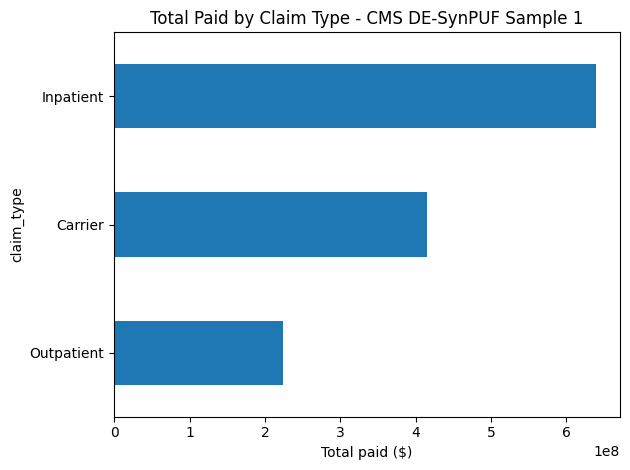

In [6]:
by_type['sum'].sort_values().plot(kind='barh')
plt.xlabel('Total paid ($)')
plt.title('Total Paid by Claim Type - CMS DE-SynPUF Sample 1')
plt.tight_layout()
plt.show()


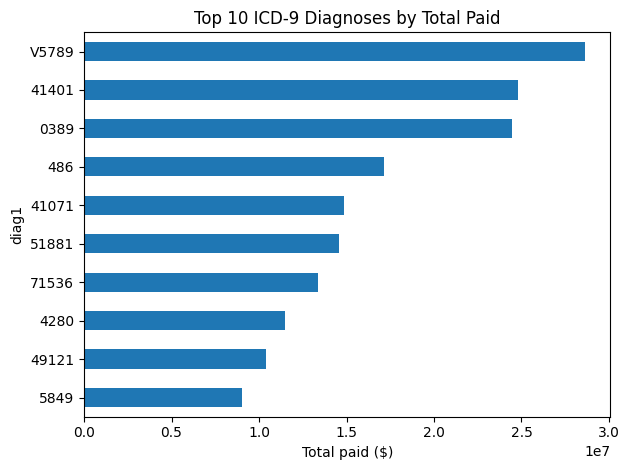

In [7]:
top_diag['sum'].sort_values().plot(kind='barh')
plt.xlabel('Total paid ($)')
plt.title('Top 10 ICD-9 Diagnoses by Total Paid')
plt.tight_layout()
plt.show()

In [8]:
dim_diag = (claims.dropna(subset=['diag1']).groupby('diag1')
  .agg(claims=('claim_id','count'), total_paid=('paid_amt','sum')).reset_index())
dim_prov = (claims.dropna(subset=['provider_id']).groupby(['provider_id','claim_type'])
  .agg(claims=('claim_id','count'), total_paid=('paid_amt','sum')).reset_index())
claims.to_csv(BASE + 'fact_claims.csv', index=False)
patient.to_csv(BASE + 'dim_patient.csv', index=False)
dim_diag.to_csv(BASE + 'dim_diagnosis.csv', index=False)
dim_prov.to_csv(BASE + 'dim_provider.csv', index=False)
print('power bi files saved')

power bi files saved
